In [ ]:
import scanpy as sc
import scvelo as scv
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from cellrank.kernels import CytoTRACEKernel

# Day 1 script #

Saving outputs to: ./trajectory_analysis_output
Loading data...
Dataset directory: /Users/work/scanpy_datasets
Computing trajectory...


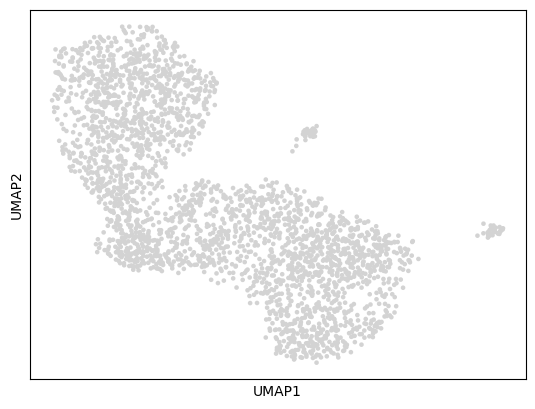

In [ ]:


output_dir = os.path.expanduser('./trajectory_analysis_output')
os.makedirs(output_dir, exist_ok=True)
print(f"Saving outputs to: {output_dir}")

# === LOAD & PREPROCESS ===
print("Loading data...")
sc.settings.datasetdir = Path.home() / "scanpy_datasets"
sc.settings.datasetdir.mkdir(parents=True, exist_ok=True)

print("Dataset directory:", sc.settings.datasetdir)
adata = sc.datasets.paul15()

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, n_top_genes=2000)

# === TRAJECTORY ===
print("Computing trajectory...")
sc.tl.pca(adata, svd_solver='arpack')
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=40)

sc.tl.umap(adata)
sc.tl.diffmap(adata)

adata.layers["spliced"] = adata.X
adata.layers["unspliced"] = adata.X
scv.pp.moments(adata, n_pcs=30, n_neighbors=30)

ctk = CytoTRACEKernel(adata).compute_cytotrace()

computing neighbors
    finished (0:00:00) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)



Available clusters:
['10GMP', '11DC', '12Baso', '13Baso', '14Mo', '15Mo', '16Neu', '17Neu', '18Eos', '19Lymph', '1Ery', '2Ery', '3Ery', '4Ery', '5Ery', '6Ery', '7MEP', '8Mk', '9GMP']
Using root cell index: 1662
Creating visualizations...


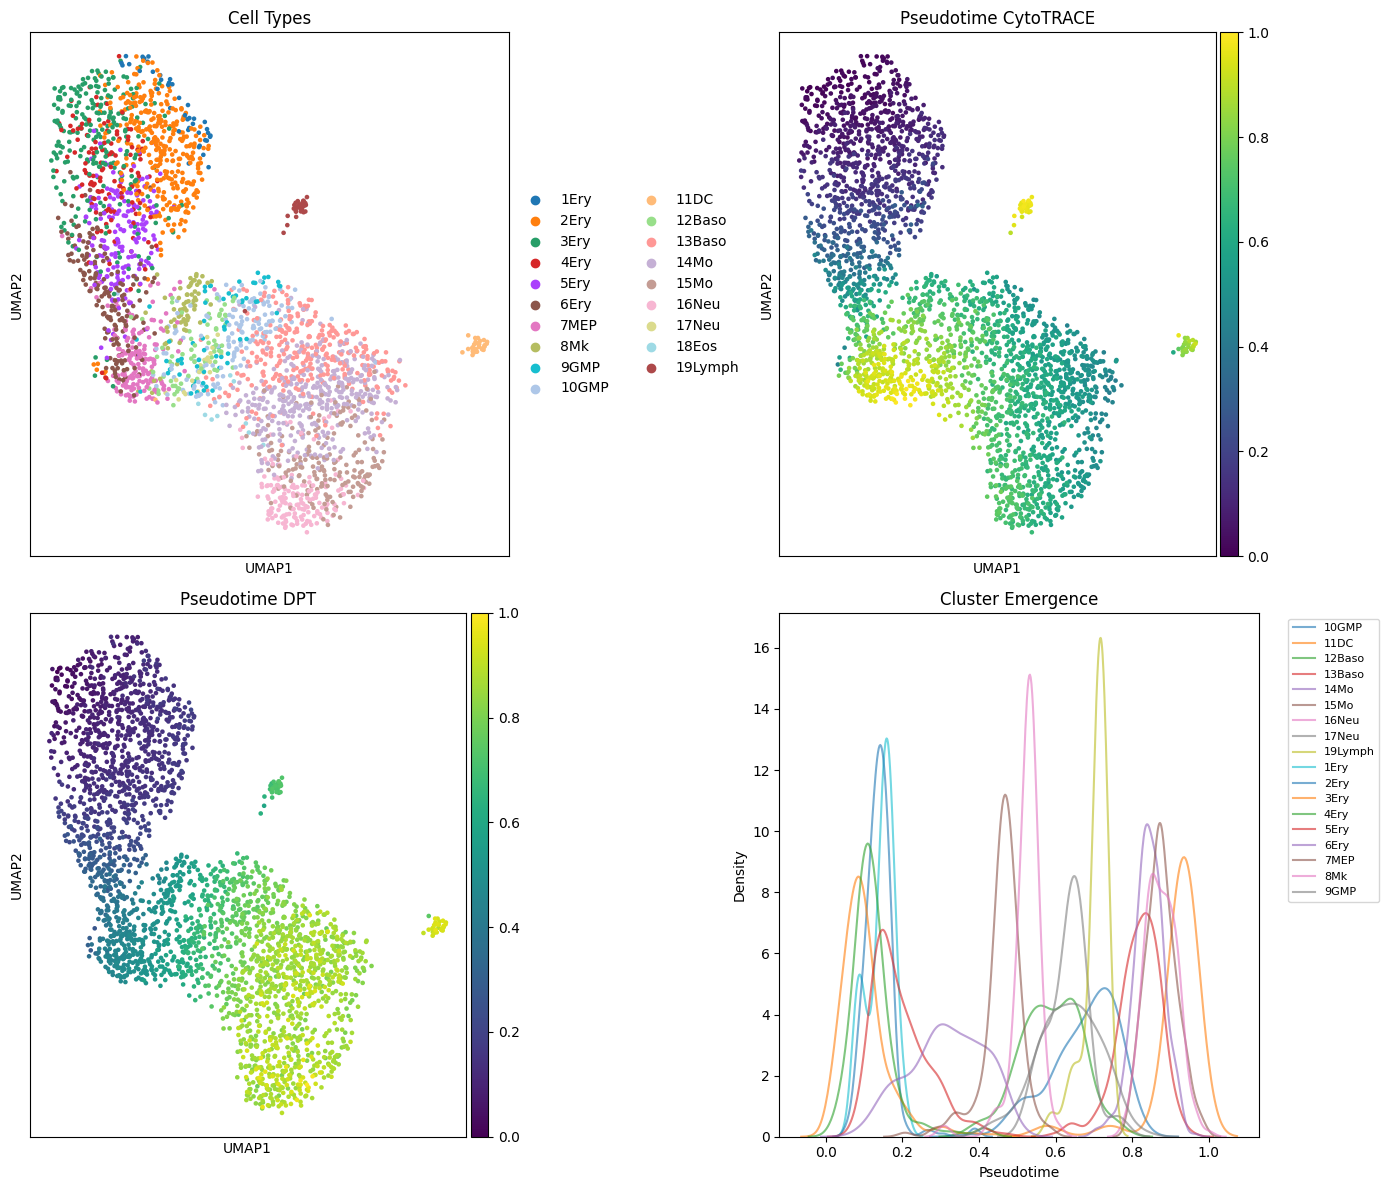


=== Pseudotime by cluster ===
                 count      mean       std
paul15_clusters                           
3Ery               246  0.102081  0.063649
4Ery               124  0.123875  0.060104
2Ery               329  0.139865  0.039622
1Ery                43  0.143078  0.034613
5Ery               180  0.195415  0.072008
6Ery               173  0.316977  0.095783
7MEP               167  0.460980  0.050500
8Mk                 68  0.524334  0.038079
12Baso              69  0.588198  0.076857
17Neu               22  0.632949  0.050862
9GMP                63  0.634696  0.079961
10GMP              153  0.674692  0.087261
19Lymph             31  0.703720  0.033394
18Eos                9  0.726436  0.082654
13Baso             300  0.817124  0.056832
14Mo               373  0.842631  0.040120
16Neu              164  0.874835  0.040395
15Mo               186  0.875929  0.039888
11DC                30  0.915199  0.074306

=== PAGA Connections (look for branch points) ===


In [80]:
# Set root
print("\nAvailable clusters:")
all_clusters = sorted(adata.obs['paul15_clusters'].unique())
print(all_clusters)

# Get integer position of lowest pseudotime cell
root_idx = adata.obs['ct_pseudotime'].values.argmin()
# Set as root
adata.uns['iroot'] = root_idx
print(f"Using root cell index: {root_idx}")

sc.tl.dpt(adata)
sc.tl.paga(adata, groups='paul15_clusters')

# === VISUALIZE ===
print("Creating visualizations...")
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

sc.pl.umap(adata, color='paul15_clusters', ax=axes[0,0], show=False, 
           title='Cell Types', legend_loc='right margin')
sc.pl.umap(adata, color='ct_pseudotime', ax=axes[0,1], show=False, 
           title='Pseudotime CytoTRACE', cmap='viridis')
sc.pl.umap(adata, color='dpt_pseudotime', ax=axes[1,0], show=False, 
           title='Pseudotime DPT', cmap='viridis')
# sc.pl.paga(adata, ax=axes[1,1], show=False, 
#            title='PAGA Branch Structure', node_size_scale=1.5, fontsize=8)

# Pseudotime density
for cluster in sorted(adata.obs['paul15_clusters'].unique()):
    cluster_cells = adata[adata.obs['paul15_clusters'] == cluster]
    if len(cluster_cells) > 10:
        sns.kdeplot(data=cluster_cells.obs['dpt_pseudotime'], 
                   label=cluster, ax=axes[1,1], alpha=0.6)
axes[1,1].set_xlabel('Pseudotime')
axes[1,1].set_ylabel('Density')
axes[1,1].set_title('Cluster Emergence')
axes[1,1].legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)

plt.tight_layout()
plt.savefig(f'{output_dir}/day1_trajectory_analysis.png', dpi=150)
plt.show()

# === IDENTIFY BIFURCATIONS ===
print("\n=== Pseudotime by cluster ===")
pt_stats = adata.obs.groupby('paul15_clusters')['dpt_pseudotime'].agg(['count', 'mean', 'std']).sort_values('mean')
print(pt_stats)

print("\n=== PAGA Connections (look for branch points) ===")
paga_conn = adata.uns['paga']['connectivities'].toarray()
cluster_names = adata.obs['paul15_clusters'].cat.categories.tolist()



In [90]:
for i, cluster in enumerate(cluster_names):
    connections = [cluster_names[j] for j in range(len(cluster_names)) if paga_conn[i,j] > 0.75]
    if len(connections) > 2:  # Bifurcation point
        print(f"⭐ {cluster} connects to: {connections} (BIFURCATION!)")
    # elif len(connections) > 0:
    #     print(f"   {cluster} connects to: {connections}")

# Save the data object
adata.write(f'{output_dir}/paul15_processed.h5ad')
print(f"\n✓ Saved processed data to: {output_dir}/paul15_processed.h5ad")

⭐ 2Ery connects to: ['1Ery', '3Ery', '4Ery', '5Ery'] (BIFURCATION!)
⭐ 3Ery connects to: ['2Ery', '4Ery', '5Ery', '6Ery'] (BIFURCATION!)
⭐ 4Ery connects to: ['2Ery', '3Ery', '5Ery', '6Ery'] (BIFURCATION!)
⭐ 5Ery connects to: ['2Ery', '3Ery', '4Ery', '6Ery'] (BIFURCATION!)
⭐ 6Ery connects to: ['3Ery', '4Ery', '5Ery', '7MEP'] (BIFURCATION!)
⭐ 7MEP connects to: ['6Ery', '8Mk', '9GMP', '12Baso', '17Neu', '18Eos'] (BIFURCATION!)
⭐ 8Mk connects to: ['7MEP', '9GMP', '10GMP', '12Baso'] (BIFURCATION!)
⭐ 9GMP connects to: ['7MEP', '8Mk', '10GMP', '12Baso', '13Baso', '17Neu'] (BIFURCATION!)
⭐ 10GMP connects to: ['8Mk', '9GMP', '12Baso', '13Baso'] (BIFURCATION!)
⭐ 12Baso connects to: ['7MEP', '8Mk', '9GMP', '10GMP', '17Neu', '18Eos'] (BIFURCATION!)
⭐ 13Baso connects to: ['9GMP', '10GMP', '14Mo'] (BIFURCATION!)
⭐ 14Mo connects to: ['13Baso', '15Mo', '18Eos'] (BIFURCATION!)
⭐ 15Mo connects to: ['14Mo', '16Neu', '18Eos'] (BIFURCATION!)
⭐ 17Neu connects to: ['7MEP', '9GMP', '12Baso', '18Eos'] (BIFURCAT

## Select bifurcation ##

In [91]:
import numpy as np

# Check pseudotime of key clusters
key_clusters = ['7MEP', '6Ery', '8Mk', '9GMP', '10GMP', '14Mo', '15Mo', '16Neu', '17Neu']
pt = adata.obs.groupby('paul15_clusters')['dpt_pseudotime'].mean()

print("=== Key cluster pseudotimes ===")
for c in key_clusters:
    if c in pt.index:
        print(f"{c}: {pt[c]:.3f}")

# Define bifurcations manually based on known biology
bifurcations = {
    'MEP_bifurcation': {
        'progenitor': '7MEP',
        'daughter1': '6Ery',   # erythroid path
        'daughter2': '8Mk',    # megakaryocyte path
        'description': 'MEP → Erythroid vs Megakaryocyte'
    },
    'GMP_bifurcation': {
        'progenitor': '9GMP',
        'daughter1': '14Mo',   # monocyte path
        'daughter2': '17Neu',  # neutrophil path
        'description': 'GMP → Monocyte vs Neutrophil'
    }
}

print("\n=== Our two target bifurcations ===")
for name, bifurc in bifurcations.items():
    print(f"\n{name}: {bifurc['description']}")
    for role, cluster in bifurc.items():
        if cluster in pt.index:
            print(f"  {role}: {cluster} (pseudotime: {pt[cluster]:.3f})")

=== Key cluster pseudotimes ===
7MEP: 0.461
6Ery: 0.317
8Mk: 0.524
9GMP: 0.635
10GMP: 0.675
14Mo: 0.843
15Mo: 0.876
16Neu: 0.875
17Neu: 0.633

=== Our two target bifurcations ===

MEP_bifurcation: MEP → Erythroid vs Megakaryocyte
  progenitor: 7MEP (pseudotime: 0.461)
  daughter1: 6Ery (pseudotime: 0.317)
  daughter2: 8Mk (pseudotime: 0.524)

GMP_bifurcation: GMP → Monocyte vs Neutrophil
  progenitor: 9GMP (pseudotime: 0.635)
  daughter1: 14Mo (pseudotime: 0.843)
  daughter2: 17Neu (pseudotime: 0.633)


In [92]:
import numpy as np

# Check pseudotime of key clusters
key_clusters = ['7MEP', '6Ery', '8Mk', '9GMP', '10GMP', '14Mo', '15Mo', '16Neu', '17Neu']
pt = adata.obs.groupby('paul15_clusters')['ct_pseudotime'].mean()

print("=== Key cluster pseudotimes ===")
for c in key_clusters:
    if c in pt.index:
        print(f"{c}: {pt[c]:.3f}")

# Define bifurcations manually based on known biology
bifurcations = {
    'MEP_bifurcation': {
        'progenitor': '7MEP',
        'daughter1': '6Ery',   # erythroid path
        'daughter2': '8Mk',    # megakaryocyte path
        'description': 'MEP → Erythroid vs Megakaryocyte'
    },
    'GMP_bifurcation': {
        'progenitor': '9GMP',
        'daughter1': '14Mo',   # monocyte path
        'daughter2': '17Neu',  # neutrophil path
        'description': 'GMP → Monocyte vs Neutrophil'
    }
}

print("\n=== Our two target bifurcations ===")
for name, bifurc in bifurcations.items():
    print(f"\n{name}: {bifurc['description']}")
    for role, cluster in bifurc.items():
        if cluster in pt.index:
            print(f"  {role}: {cluster} (pseudotime: {pt[cluster]:.3f})")

=== Key cluster pseudotimes ===
7MEP: 0.872
6Ery: 0.557
8Mk: 0.736
9GMP: 0.762
10GMP: 0.737
14Mo: 0.604
15Mo: 0.607
16Neu: 0.673
17Neu: 0.892

=== Our two target bifurcations ===

MEP_bifurcation: MEP → Erythroid vs Megakaryocyte
  progenitor: 7MEP (pseudotime: 0.872)
  daughter1: 6Ery (pseudotime: 0.557)
  daughter2: 8Mk (pseudotime: 0.736)

GMP_bifurcation: GMP → Monocyte vs Neutrophil
  progenitor: 9GMP (pseudotime: 0.762)
  daughter1: 14Mo (pseudotime: 0.604)
  daughter2: 17Neu (pseudotime: 0.892)


Loading data...
Computing trajectory...


/var/folders/tb/mtqjrwzn04v2ws67ymnhmv5h0000gp/T/ipykernel_99105/2478206102.py:32: DeprecationWarning: Automatic neighbor calculation is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors first with Scanpy.
  scv.pp.moments(adata, n_pcs=30, n_neighbors=30)
/opt/miniconda3/envs/causal_cell_decisions/lib/python3.12/site-packages/scvelo/preprocessing/moments.py:71: DeprecationWarning: `neighbors` is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors with Scanpy.
  neighbors(


computing neighbors
    finished (0:00:00) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)

Setting root cell...
Root cell: index 65, cluster 7MEP
Root CytoTRACE score: 0.321

=== Pseudotime sanity check ===

Cluster           DPT    CytoTRACE  Expected order
--------------------------------------------------
7MEP            0.324        0.872  earliest (progenitor)
6Ery            0.166        0.557  middle-late
8Mk             0.402        0.736  middle-late
9GMP            0.540        0.762  middle
10GMP           0.590        0.737  middle
14Mo            0.800        0.604  late
16Neu           0.841        0.673  late
17Neu           0.538        0.892  late

✓ 7MEP should have LOWEST DPT
✓ 7MEP should have LOWEST CytoTRACE (ct_pseudotime is inverted)
✓ 14Mo, 16Neu, 17Neu should have HIGHEST DPT



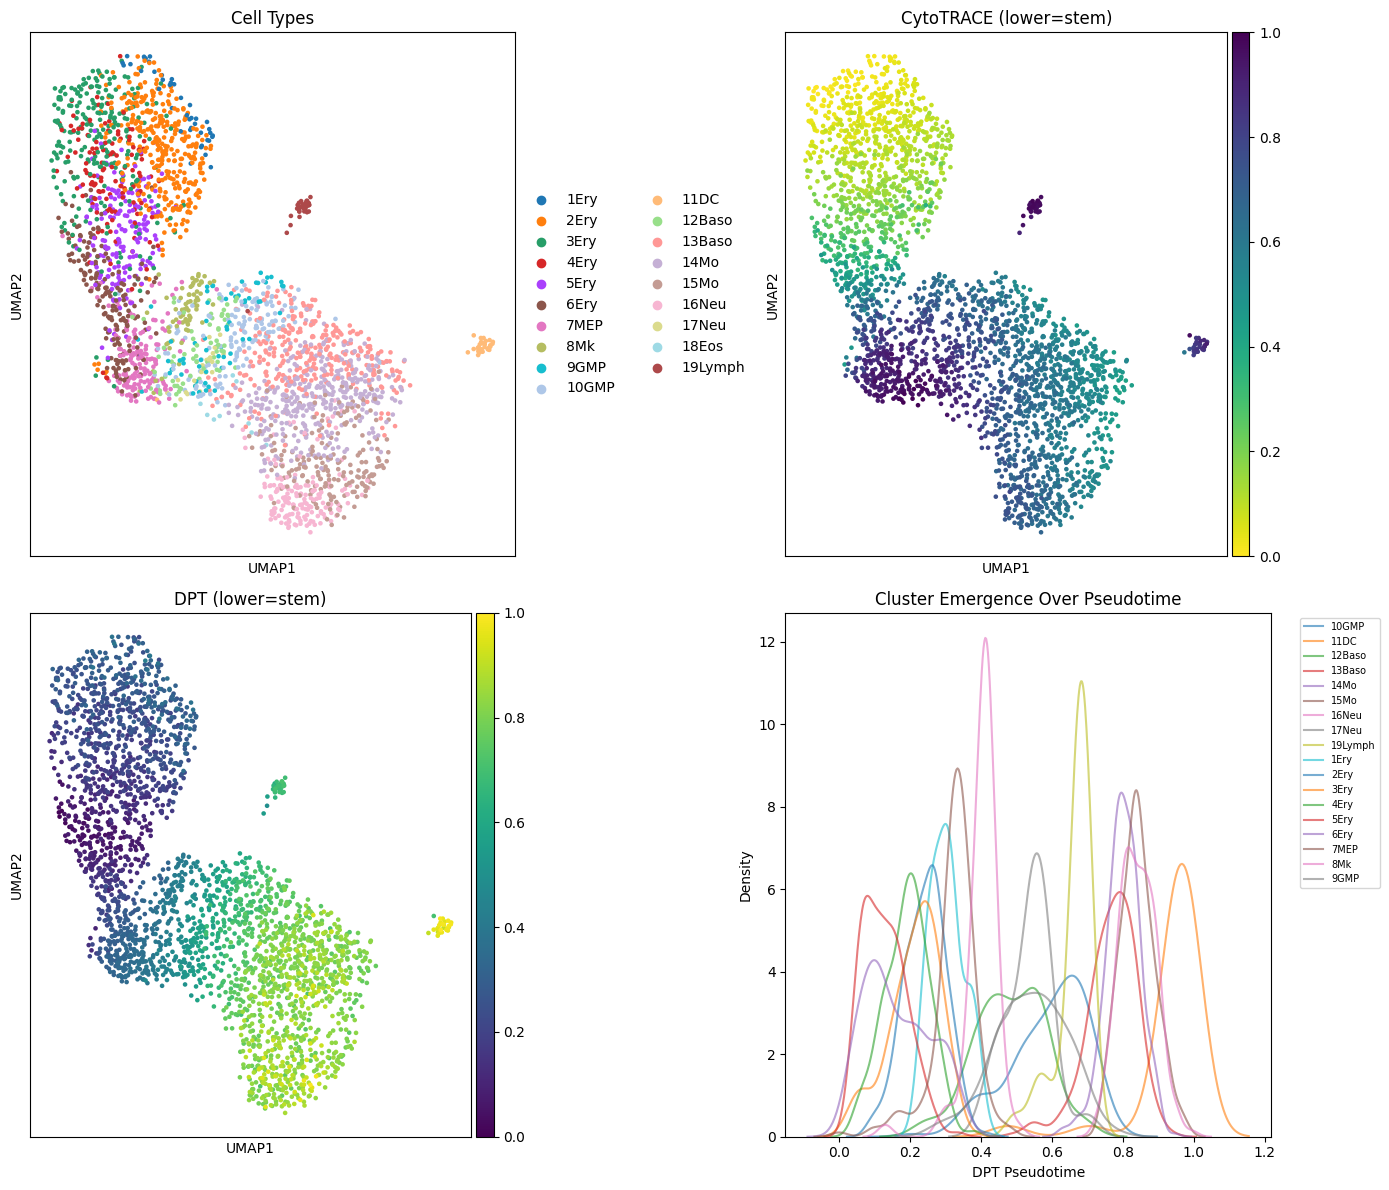


✓ Saved to ./trajectory_analysis_output/paul15_processed.h5ad

Next step: extract cells at bifurcations for causal discovery


In [93]:
import os
import scanpy as sc
import scvelo as scv
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from cellrank.kernels import CytoTRACEKernel
from pathlib import Path

output_dir = os.path.expanduser('./trajectory_analysis_output')
os.makedirs(output_dir, exist_ok=True)

# === LOAD & PREPROCESS ===
print("Loading data...")
sc.settings.datasetdir = Path.home() / "scanpy_datasets"
sc.settings.datasetdir.mkdir(parents=True, exist_ok=True)
adata = sc.datasets.paul15()

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, n_top_genes=2000)

# === TRAJECTORY ===
print("Computing trajectory...")
sc.tl.pca(adata, svd_solver='arpack')
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=40)
sc.tl.umap(adata)
sc.tl.diffmap(adata)

adata.layers["spliced"] = adata.X
adata.layers["unspliced"] = adata.X
scv.pp.moments(adata, n_pcs=30, n_neighbors=30)

ctk = CytoTRACEKernel(adata).compute_cytotrace()

# === FIX ROOT: use most stem-like cell WITHIN 7MEP ===
# CytoTRACE: higher = more stem-like
# So root = 7MEP cell with HIGHEST cytotrace score
print("\nSetting root cell...")
mep_mask = adata.obs['paul15_clusters'] == '7MEP'
mep_indices = np.where(mep_mask)[0]
mep_cytotrace = adata.obs['ct_pseudotime'].values[mep_indices]

# ct_pseudotime is INVERTED (lower = more stem-like), so take argmin
root_idx = mep_indices[np.argmin(mep_cytotrace)]
adata.uns['iroot'] = root_idx

print(f"Root cell: index {root_idx}, cluster 7MEP")
print(f"Root CytoTRACE score: {adata.obs['ct_pseudotime'].values[root_idx]:.3f}")

# === PSEUDOTIME ===
sc.tl.dpt(adata)
sc.tl.paga(adata, groups='paul15_clusters')

# === SANITY CHECK: is ordering correct? ===
print("\n=== Pseudotime sanity check ===")
key_clusters = ['7MEP', '6Ery', '8Mk', '9GMP', '10GMP', '14Mo', '16Neu', '17Neu']
pt_dpt = adata.obs.groupby('paul15_clusters')['dpt_pseudotime'].mean()
pt_ct  = adata.obs.groupby('paul15_clusters')['ct_pseudotime'].mean()

print(f"\n{'Cluster':<12} {'DPT':>8} {'CytoTRACE':>12}  {'Expected order'}")
print("-" * 50)
expected = {
    '7MEP':  'earliest (progenitor)',
    '6Ery':  'middle-late',
    '8Mk':   'middle-late',
    '9GMP':  'middle',
    '10GMP': 'middle',
    '14Mo':  'late',
    '16Neu': 'late',
    '17Neu': 'late'
}
for c in key_clusters:
    if c in pt_dpt.index:
        print(f"{c:<12} {pt_dpt[c]:>8.3f} {pt_ct[c]:>12.3f}  {expected.get(c, '')}")

print("\n✓ 7MEP should have LOWEST DPT")
print("✓ 7MEP should have LOWEST CytoTRACE (ct_pseudotime is inverted)")
print("✓ 14Mo, 16Neu, 17Neu should have HIGHEST DPT")

# === IDENTIFY BIFURCATIONS PROPERLY ===
# Instead of threshold tuning, use known biology + pseudotime ordering
print("\n=== Defining bifurcations from known biology ===")

# Verify with PAGA at a strict threshold
paga_conn = adata.uns['paga']['connectivities'].toarray()
cluster_names = adata.obs['paul15_clusters'].cat.categories.tolist()

print("\nStrict PAGA connections (threshold=0.5):")
for i, cluster in enumerate(cluster_names):
    connections = [cluster_names[j] for j in range(len(cluster_names)) 
                  if paga_conn[i,j] > 0.5]
    if connections:
        print(f"  {cluster} → {connections}")

# Hard-code the two known bifurcations
bifurcations = {
    'MEP': {
        'progenitor':  '7MEP',
        'daughter1':   '6Ery',
        'daughter2':   '8Mk',
        'description': 'MEP → Erythroid vs Megakaryocyte'
    },
    'GMP': {
        'progenitor':  '9GMP',
        'daughter1':   '14Mo',
        'daughter2':   '17Neu',
        'description': 'GMP → Monocyte vs Neutrophil'
    }
}

print("\n=== Bifurcation pseudotime check ===")
for name, b in bifurcations.items():
    print(f"\n{name} bifurcation: {b['description']}")
    for role, cluster in b.items():
        if role == 'description':
            continue
        dpt = pt_dpt.get(cluster, float('nan'))
        ct  = pt_ct.get(cluster, float('nan'))
        print(f"  {role:<12} {cluster:<8}  DPT={dpt:.3f}  CytoTRACE={ct:.3f}")
    
    # Check ordering: progenitor should have lower DPT than daughters
    prog_dpt = pt_dpt.get(b['progenitor'], float('nan'))
    d1_dpt   = pt_dpt.get(b['daughter1'],  float('nan'))
    d2_dpt   = pt_dpt.get(b['daughter2'],  float('nan'))
    
    if prog_dpt < d1_dpt and prog_dpt < d2_dpt:
        print(f"  ✓ Ordering correct: {b['progenitor']} is earlier than daughters")
    else:
        print(f"  ✗ Ordering WRONG - pseudotime still needs fixing")

# === VISUALIZE ===
print("\nCreating visualizations...")
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

sc.pl.umap(adata, color='paul15_clusters', ax=axes[0,0], show=False,
           title='Cell Types', legend_loc='right margin')
sc.pl.umap(adata, color='ct_pseudotime', ax=axes[0,1], show=False,
           title='CytoTRACE (lower=stem)', cmap='viridis_r')
sc.pl.umap(adata, color='dpt_pseudotime', ax=axes[1,0], show=False,
           title='DPT (lower=stem)', cmap='viridis')

for cluster in sorted(adata.obs['paul15_clusters'].unique()):
    cells = adata[adata.obs['paul15_clusters'] == cluster]
    if len(cells) > 10:
        sns.kdeplot(data=cells.obs['dpt_pseudotime'],
                   label=cluster, ax=axes[1,1], alpha=0.6)
axes[1,1].set_xlabel('DPT Pseudotime')
axes[1,1].set_ylabel('Density')
axes[1,1].set_title('Cluster Emergence Over Pseudotime')
axes[1,1].legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=7)

plt.tight_layout()
plt.savefig(f'{output_dir}/trajectory_analysis.png', dpi=150)
plt.show()

# === SAVE ===
adata.write(f'{output_dir}/paul15_processed.h5ad')
print(f"\n✓ Saved to {output_dir}/paul15_processed.h5ad")
print("\nNext step: extract cells at bifurcations for causal discovery")


In [96]:
adata.obs

,paul15_clusters,ct_score,ct_pseudotime,ct_num_exp_genes,dpt_pseudotime,cytotrace_pseudotime
W31105,7MEP,0.045871,0.954129,277,0.354885,0.045871
W31106,15Mo,0.423541,0.576459,1021,0.789499,0.423541
W31107,3Ery,0.989374,0.010626,1466,0.245726,0.989374
W31108,15Mo,0.518842,0.481158,1415,0.817641,0.518842
W31109,3Ery,0.988733,0.011267,1505,0.325090,0.988733
...,...,...,...,...,...,...
W39164,2Ery,0.894696,0.105304,1401,0.173216,0.894696
W39165,13Baso,0.487493,0.512507,1209,0.842041,0.487493
W39166,7MEP,0.080251,0.919749,322,0.343314,0.080251
W39167,15Mo,0.483599,0.516401,1196,0.833154,0.483599


In [ ]:
# CytoTRACE: higher score = more stem-like = EARLIER in development
# So we invert it to get a "pseudotime" where 0=early, 1=late
# adata.obs['cytotrace_pseudotime'] = 1 - adata.obs['ct_score']
adata.obs['cytotrace_pseudotime'] = 1 - adata.obs['ct_pseudotime']


# NOTE: ct_pseudotime from CellRank is already this inverted version
# Let's verify:
print("=== CytoTRACE as pseudotime (lower = earlier) ===")
key_clusters = ['7MEP', '6Ery', '8Mk', '9GMP', '10GMP', '14Mo', '16Neu', '17Neu']
pt_ct = adata.obs.groupby('paul15_clusters')['ct_pseudotime'].mean()

expected_order = ['7MEP', '8Mk', '9GMP', '10GMP', '6Ery', '14Mo', '16Neu', '17Neu']
print(f"\n{'Cluster':<12} {'CytoTRACE PT':>14}  {'Expected role'}")
print("-" * 50)
roles = {
    '7MEP':  'progenitor (earliest)',
    '8Mk':   'megakaryocyte',
    '9GMP':  'myeloid progenitor',
    '10GMP': 'myeloid progenitor',
    '6Ery':  'erythroid',
    '14Mo':  'monocyte (late)',
    '16Neu': 'neutrophil (late)',
    '17Neu': 'neutrophil (late)'
}
for c in sorted(key_clusters, key=lambda x: pt_ct.get(x, 0)):
    print(f"{c:<12} {pt_ct[c]:>14.3f}  {roles.get(c, '')}")

# === REDEFINE BIFURCATIONS USING CYTOTRACE ===
# With CytoTRACE: progenitor should have LOWER ct_pseudotime than daughters
bifurcations = {
    'MEP': {
        'progenitor': '7MEP',
        'daughter1':  '6Ery',
        'daughter2':  '8Mk',
        'description': 'MEP → Erythroid vs Megakaryocyte'
    },
    'GMP': {
        'progenitor': '9GMP',
        'daughter1':  '14Mo',
        'daughter2':  '16Neu',   # switched from 17Neu
        'description': 'GMP → Monocyte vs Neutrophil'w}}

print("\n=== Bifurcation verification (using CytoTRACE) ===")
for name, b in bifurcations.items():
    prog_pt = pt_ct.get(b['progenitor'], float('nan'))
    d1_pt   = pt_ct.get(b['daughter1'],  float('nan'))
    d2_pt   = pt_ct.get(b['daughter2'],  float('nan'))
    
    print(f"\n{name}: {b['description']}")
    print(f"  {b['progenitor']:<8} (progenitor) ct_pseudotime={prog_pt:.3f}")
    print(f"  {b['daughter1']:<8} (daughter 1) ct_pseudotime={d1_pt:.3f}")
    print(f"  {b['daughter2']:<8} (daughter 2) ct_pseudotime={d2_pt:.3f}")
    
    if prog_pt < d1_pt and prog_pt < d2_pt:
        print(f"  ✓ Correct: {b['progenitor']} is earlier than both daughters")
    else:
        print(f"  ✗ Still wrong - check cluster assignments")

=== CytoTRACE as pseudotime (lower = earlier) ===

Cluster        CytoTRACE PT  Expected role
--------------------------------------------------
6Ery                  0.557  erythroid
14Mo                  0.604  monocyte (late)
16Neu                 0.673  neutrophil (late)
8Mk                   0.736  megakaryocyte
10GMP                 0.737  myeloid progenitor
9GMP                  0.762  myeloid progenitor
7MEP                  0.872  progenitor (earliest)
17Neu                 0.892  neutrophil (late)

=== Bifurcation verification (using CytoTRACE) ===

MEP: MEP → Erythroid vs Megakaryocyte
  7MEP     (progenitor) ct_pseudotime=0.872
  6Ery     (daughter 1) ct_pseudotime=0.557
  8Mk      (daughter 2) ct_pseudotime=0.736
  ✗ Still wrong - check cluster assignments

GMP: GMP → Monocyte vs Neutrophil
  9GMP     (progenitor) ct_pseudotime=0.762
  14Mo     (daughter 1) ct_pseudotime=0.604
  16Neu    (daughter 2) ct_pseudotime=0.673
  ✗ Still wrong - check cluster assignments


In [100]:
adata = sc.read("https://www.ebi.ac.uk/biostudies/files/E-MTAB-6795/planarian_plass2018.h5ad")


FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = 'https:/www.ebi.ac.uk/biostudies/files/E-MTAB-6795/planarian_plass2018.h5ad', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

In [101]:
adata = sc.read("packer2019_celegans.h5ad")  # needs download


FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = 'packer2019_celegans.h5ad', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

In [104]:
sc.settings.datasetdir = Path.home() / "scanpy_datasets"
sc.settings.datasetdir.mkdir(parents=True, exist_ok=True)

print("Dataset directory:", sc.settings.datasetdir)


Dataset directory: /Users/work/scanpy_datasets


## Moignard 15 ##

Loading Moignard et al. 2015...


/opt/miniconda3/envs/causal_cell_decisions/lib/python3.12/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


Loaded: 3934 cells, 42 genes
This is a qPCR dataset - 42 developmental regulator genes!
Converting data to float32...

Genes: Cbfa2t3h, Cdh1, Cdh5, Egfl7, Erg, Ets1, Ets2, Etv2, Etv6, Fli1, FoxH1, FoxO4, Gata1, Gfi1, Gfi1b...

Experimental groups: ['HF', 'NP', 'PS', '4SG', '4SFG']
Categories (5, object): ['HF', 'NP', 'PS', '4SG', '4SFG']

Cells per group:
exp_groups
HF      1005
4SG      983
4SFG     770
PS       624
NP       552
Name: count, dtype: int64

Preprocessing...
Computing pseudotime with DPT...
Using pre-set root cell: 532
Creating visualizations...


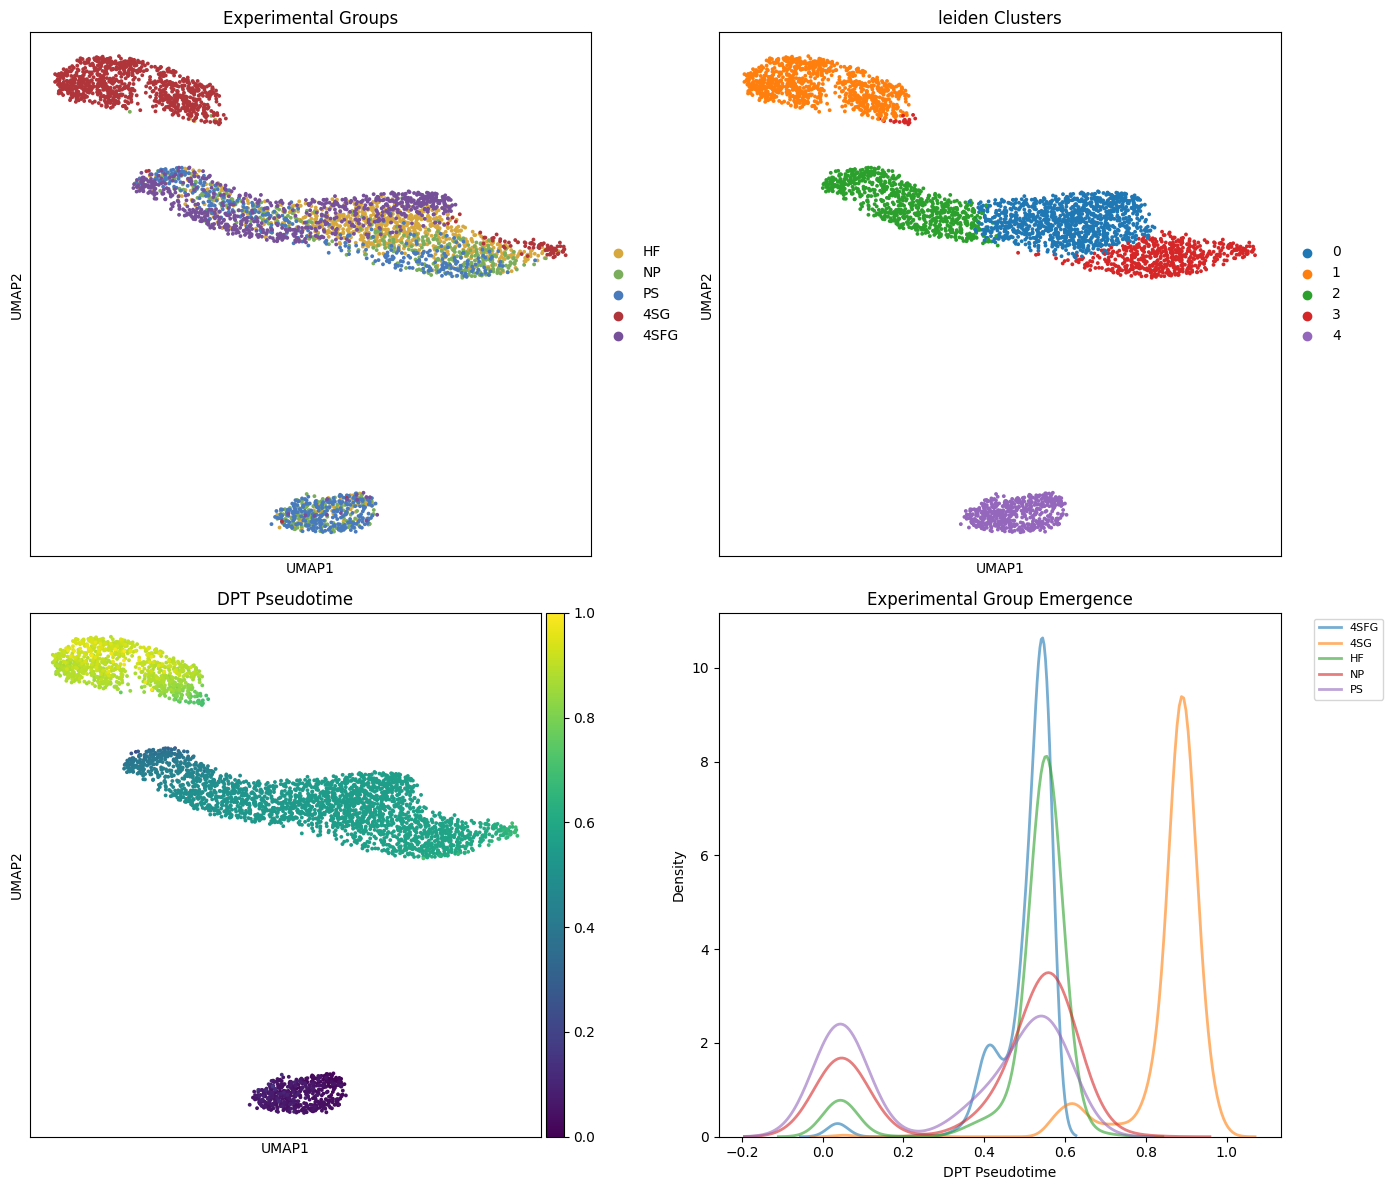


=== Pseudotime by experimental group ===
                mean       std  count
exp_groups                           
PS          0.319578  0.237639    624
NP          0.402572  0.231448    552
HF          0.502967  0.146053   1005
4SFG        0.504015  0.082834    770
4SG         0.862704  0.093281    983

=== Pseudotime by leiden cluster ===
            mean       std  count
leiden                           
4       0.045366  0.021537    519
2       0.469952  0.056445    804
0       0.549968  0.008169   1134
3       0.590537  0.032419    582
1       0.887715  0.036678    895

Computing PAGA...


/var/folders/tb/mtqjrwzn04v2ws67ymnhmv5h0000gp/T/ipykernel_99105/187894256.py:96: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


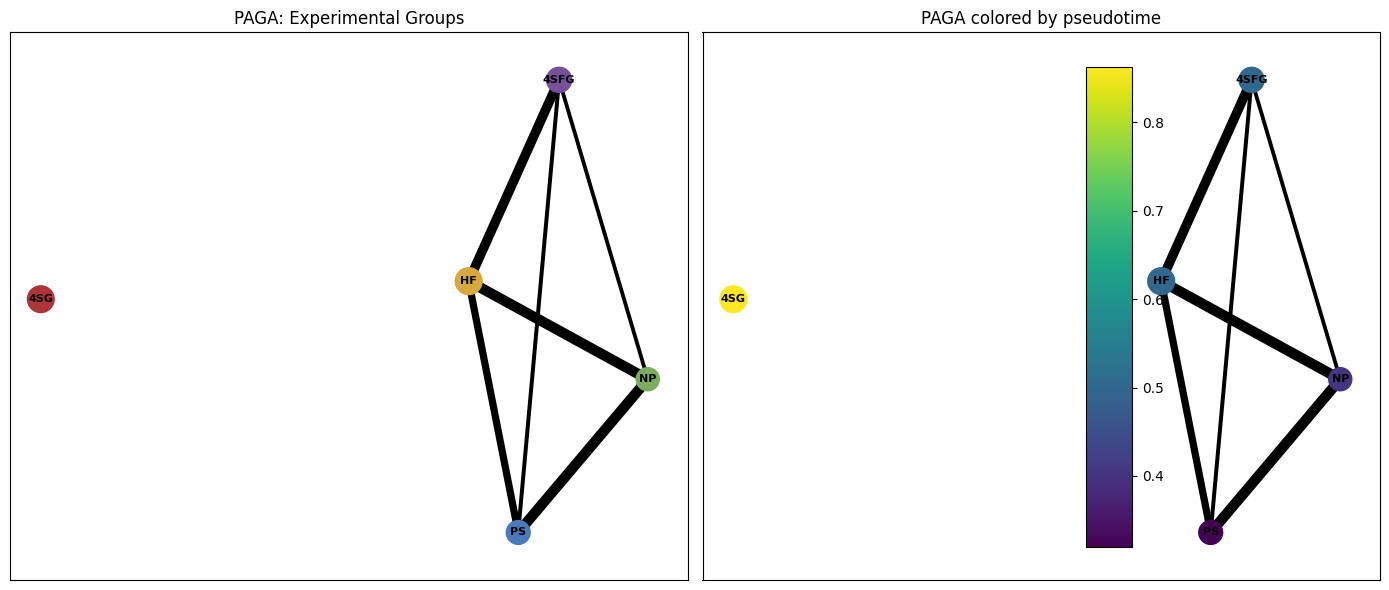

/var/folders/tb/mtqjrwzn04v2ws67ymnhmv5h0000gp/T/ipykernel_99105/187894256.py:110: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


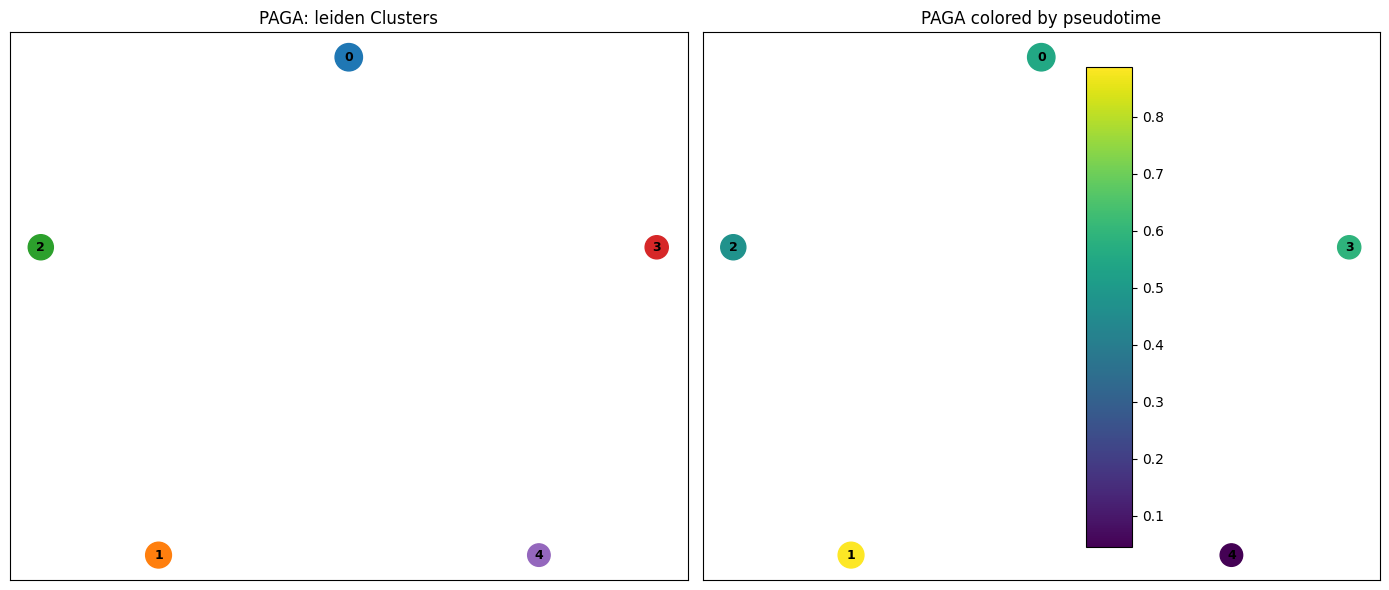


=== PAGA Connections by Cluster (threshold=0.3) ===

DATASET SUMMARY
Cells: 3934
Genes: 42 (all developmental regulators!)
Experimental groups: 5
leiden clusters: 5
Potential bifurcations: 0

No clear bifurcations at threshold 0.3
Try threshold 0.5 or use experimental groups instead of clusters

✓ Saved to ./trajectory_analysis_output/moignard_processed.h5ad


In [130]:
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

output_dir = os.path.expanduser('./trajectory_analysis_output')
os.makedirs(output_dir, exist_ok=True)

# === LOAD MOIGNARD DATA ===
print("Loading Moignard et al. 2015...")
adata = sc.datasets.moignard15()

print(f"Loaded: {adata.n_obs} cells, {adata.n_vars} genes")
print(f"This is a qPCR dataset - 42 developmental regulator genes!")

# Fix data type issue
if hasattr(adata.X, 'dtype') and adata.X.dtype == object:
    print("Converting data to float32...")
    adata.X = adata.X.astype(np.float32)

print(f"\nGenes: {', '.join(adata.var_names.tolist()[:15])}...")
print(f"\nExperimental groups: {adata.obs['exp_groups'].unique()}")
print(f"\nCells per group:\n{adata.obs['exp_groups'].value_counts()}")

# === PREPROCESS ===
print("\nPreprocessing...")
sc.pp.neighbors(adata, n_neighbors=30)
sc.tl.umap(adata)
sc.tl.leiden(adata, resolution=0.5)

# === TRAJECTORY - Use DPT (simpler, no CytoTRACE issues) ===
print("Computing pseudotime with DPT...")
sc.tl.diffmap(adata)

# The dataset already has iroot set - use it
if 'iroot' in adata.uns:
    print(f"Using pre-set root cell: {adata.uns['iroot']}")
else:
    # Find root: experimental group with most stem-like name or lowest cluster
    root_group = adata.obs['exp_groups'].value_counts().index[0]
    root_mask = adata.obs['exp_groups'] == root_group
    adata.uns['iroot'] = np.where(root_mask)[0][0]
    print(f"Set root to first cell in group: {root_group}")

sc.tl.dpt(adata)

# === VISUALIZE ===
print("Creating visualizations...")
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

sc.pl.umap(adata, color='exp_groups', ax=axes[0,0], show=False,
           title='Experimental Groups', legend_loc='right margin')
sc.pl.umap(adata, color='leiden', ax=axes[0,1], show=False,
           title='leiden Clusters', legend_loc='right margin')
sc.pl.umap(adata, color='dpt_pseudotime', ax=axes[1,0], show=False,
           title='DPT Pseudotime', cmap='viridis')

# Density by experimental group
for group in sorted(adata.obs['exp_groups'].unique()):
    cells = adata[adata.obs['exp_groups'] == group]
    if len(cells) > 10:
        sns.kdeplot(data=cells.obs['dpt_pseudotime'],
                   label=group, ax=axes[1,1], alpha=0.6, linewidth=2)
axes[1,1].set_xlabel('DPT Pseudotime')
axes[1,1].set_ylabel('Density')
axes[1,1].set_title('Experimental Group Emergence')
axes[1,1].legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)

plt.tight_layout()
plt.savefig(f'{output_dir}/moignard_overview.png', dpi=150)
plt.show()

# === PSEUDOTIME ANALYSIS ===
print("\n=== Pseudotime by experimental group ===")
pt_by_group = adata.obs.groupby('exp_groups')['dpt_pseudotime'].agg(['mean', 'std', 'count']).sort_values('mean')
print(pt_by_group)

print("\n=== Pseudotime by leiden cluster ===")
pt_by_cluster = adata.obs.groupby('leiden')['dpt_pseudotime'].agg(['mean', 'std', 'count']).sort_values('mean')
print(pt_by_cluster)

# === PAGA ===
print("\nComputing PAGA...")

# PAGA on experimental groups
sc.tl.paga(adata, groups='exp_groups')
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sc.pl.paga(adata, threshold=0.1, ax=axes[0], show=False,
           title='PAGA: Experimental Groups',
           node_size_scale=2, fontsize=8)
sc.pl.paga(adata, threshold=0.1, ax=axes[1], show=False,
           color='dpt_pseudotime',
           title='PAGA colored by pseudotime',
           node_size_scale=2, fontsize=8)
plt.tight_layout()
plt.savefig(f'{output_dir}/moignard_paga_groups.png', dpi=150)
plt.show()

# PAGA on clusters
sc.tl.paga(adata, groups='leiden')
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sc.pl.paga(adata, threshold=0.3, ax=axes[0], show=False,
           title='PAGA: leiden Clusters',
           node_size_scale=2, fontsize=9)
sc.pl.paga(adata, threshold=0.3, ax=axes[1], show=False,
           color='dpt_pseudotime',
           title='PAGA colored by pseudotime',
           node_size_scale=2, fontsize=9)
plt.tight_layout()
plt.savefig(f'{output_dir}/moignard_paga_clusters.png', dpi=150)
plt.show()

# === IDENTIFY BIFURCATIONS ===
print("\n=== PAGA Connections by Cluster (threshold=0.3) ===")
paga_conn = adata.uns['paga']['connectivities'].toarray()
cluster_names = adata.obs['leiden'].cat.categories.tolist()

bifurcations = []
for i, cluster in enumerate(cluster_names):
    connections = [cluster_names[j] for j in range(len(cluster_names))
                  if paga_conn[i,j] > 0.3]
    if len(connections) > 2:
        print(f"⭐ Cluster {cluster} → {connections} (BIFURCATION!)")
        bifurcations.append(cluster)
    elif len(connections) > 0:
        print(f"   Cluster {cluster} → {connections}")

# === SUMMARY ===
print("\n" + "="*60)
print("DATASET SUMMARY")
print("="*60)
print(f"Cells: {adata.n_obs}")
print(f"Genes: {adata.n_vars} (all developmental regulators!)")
print(f"Experimental groups: {len(adata.obs['exp_groups'].unique())}")
print(f"leiden clusters: {len(adata.obs['leiden'].unique())}")
print(f"Potential bifurcations: {len(bifurcations)}")

if bifurcations:
    print(f"\nBifurcation clusters: {bifurcations}")
    print("\nNext step: Pick one bifurcation and extract cells")
else:
    print("\nNo clear bifurcations at threshold 0.3")
    print("Try threshold 0.5 or use experimental groups instead of clusters")

# Save
adata.write(f'{output_dir}/moignard_processed.h5ad')
print(f"\n✓ Saved to {output_dir}/moignard_processed.h5ad")